# F4.8 — Figura ilustrativa de la dirección discriminativa

**Sin peso argumentativo** (`docs/plan_fase4.md`, F4.8): la figura solo ilustra; no sustenta ninguna conclusión y no tiene métricas.

**Nota.** Las imágenes de la figura se renderizan con la versión actual del generador, son ilustrativas y pueden no coincidir píxel a píxel con las del conjunto de entrenamiento.

**Procedencia.** `python -m src.fase4.figura_ilustrativa --resoluciones results/f48_figura/resoluciones.json` (`results/f48_figura/recorridos.json`, `imagenes/`, dos figuras). Este notebook solo muestra esas salidas.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
D = REPO / 'results' / 'f48_figura'
DOC = json.loads((D / 'recorridos.json').read_text(encoding='utf-8'))
M = DOC['meta']
pd.set_option('display.max_colwidth', 110)
pd.DataFrame([('git_commit', M['git_commit']), ('resoluciones', f"{M['resoluciones']['archivo']} · {M['resoluciones']['sha256']}"),
              ('LogReg (F2.1)', json.dumps(M['logreg']['combinacion'])),
              ('p_dep de val frente al CSV de F2.1 (máx. |Δ|)', M['logreg']['p_dep_val_max_abs_diff']),
              ('dirección', f"espacio {DOC['direccion']['espacio']}; ŵ = {[round(x, 4) for x in DOC['direccion']['w_unitario']]}"),
              ('DE del recorrido', DOC['direccion']['de_recorrido']), ('segundos', M['segundos_total'])],
             columns=['concepto', 'valor'])

,concepto,valor
0,git_commit,c578878800478e96a9523e78011ed5c27b395d7d
1,resoluciones,results/f48_figura/resoluciones.json · c0381dd9fcb4a7845625fe7c7d2ff97949f6d6ef8f8aaaea0b9a76ae9164a802
2,LogReg (F2.1),"{""C"": 0.1, ""class_weight"": ""balanced""}"
3,p_dep de val frente al CSV de F2.1 (máx. |Δ|),0.0
4,dirección,"espacio u; ŵ = [0.5719, 0.1335, 0.097, 0.1071, -0.7964]"
5,DE del recorrido,0.377908
6,segundos,164.3


## Recorridos (puntos en u, recorte y p_dep de la LogReg)

In [2]:
rows = []
for r, x in DOC['recorridos'].items():
    for j, (u, tick, rec, p) in enumerate(zip(x['u'], x['ticks'], x['recortado'], x['p_dep_logreg'])):
        rows.append({'recorrido': x['etiqueta'], 'punto': tick, **{f'u{i}': round(v, 4) for i, v in enumerate(u)},
                     'recortado': rec, 'p_dep LogReg': round(p, 4)})
pd.DataFrame(rows)

,recorrido,punto,u0,u1,u2,u3,u4,recortado,p_dep LogReg
0,centroide 0 → 1,t=0.00,0.3282,0.5278,0.6876,0.7091,0.7137,False,0.1594
1,centroide 0 → 1,t=0.17,0.4077,0.5144,0.6305,0.6580,0.6311,False,0.2478
2,centroide 0 → 1,t=0.33,0.4871,0.5009,0.5735,0.6069,0.5485,False,0.3640
3,centroide 0 → 1,t=0.50,0.5665,0.4875,0.5164,0.5558,0.4660,False,0.4986
4,centroide 0 → 1,t=0.67,0.6459,0.4740,0.4593,0.5047,0.3834,False,0.6334
5,centroide 0 → 1,t=0.83,0.7253,0.4606,0.4023,0.4536,0.3008,False,0.7501
6,centroide 0 → 1,t=1.00,0.8047,0.4471,0.3452,0.4025,0.2182,False,0.8391
7,±1.5 DE sobre ŵ,-1.50 DE,0.1893,0.4208,0.4995,0.5292,0.9725,False,0.0277
8,±1.5 DE sobre ŵ,-1.00 DE,0.2973,0.4460,0.5178,0.5495,0.8220,False,0.0761
9,±1.5 DE sobre ŵ,-0.50 DE,0.4054,0.4712,0.5362,0.5697,0.6716,False,0.1923


## Figura en escala de grises

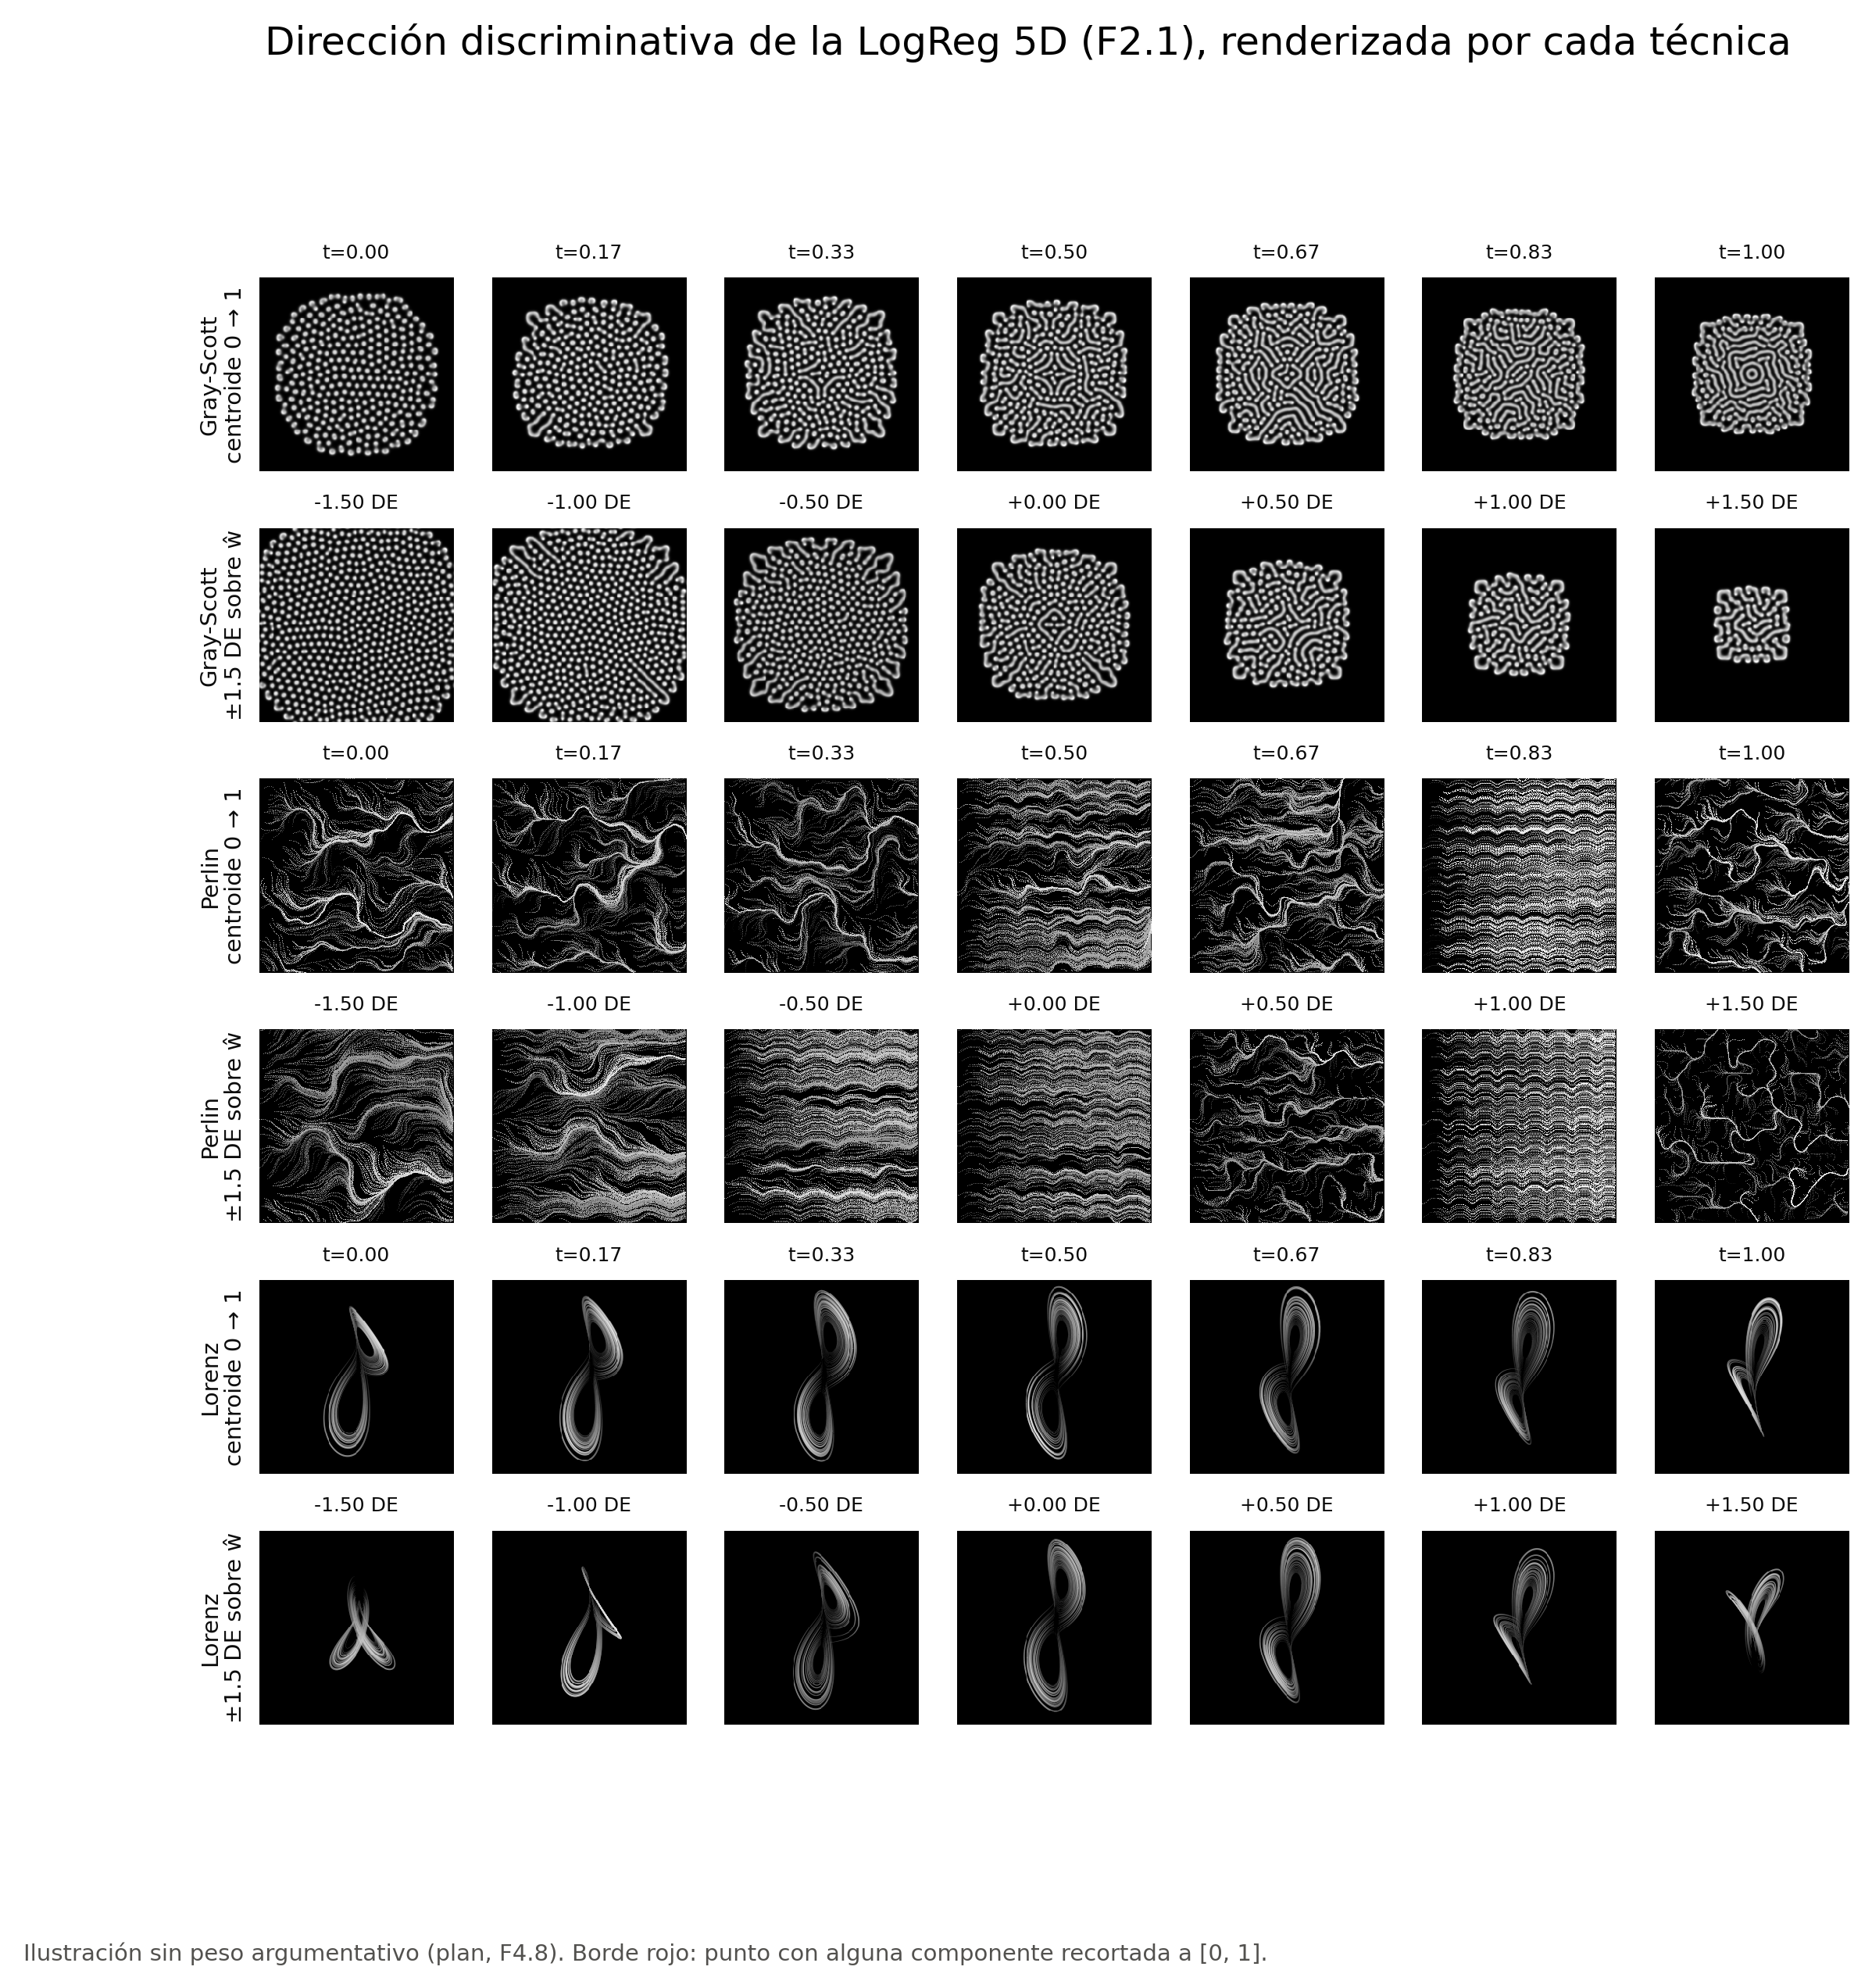

In [3]:
display(Image(filename=str(D / 'f48_direccion_grises.png'), width=900))

## Versión con paleta (solo ilustrativa)

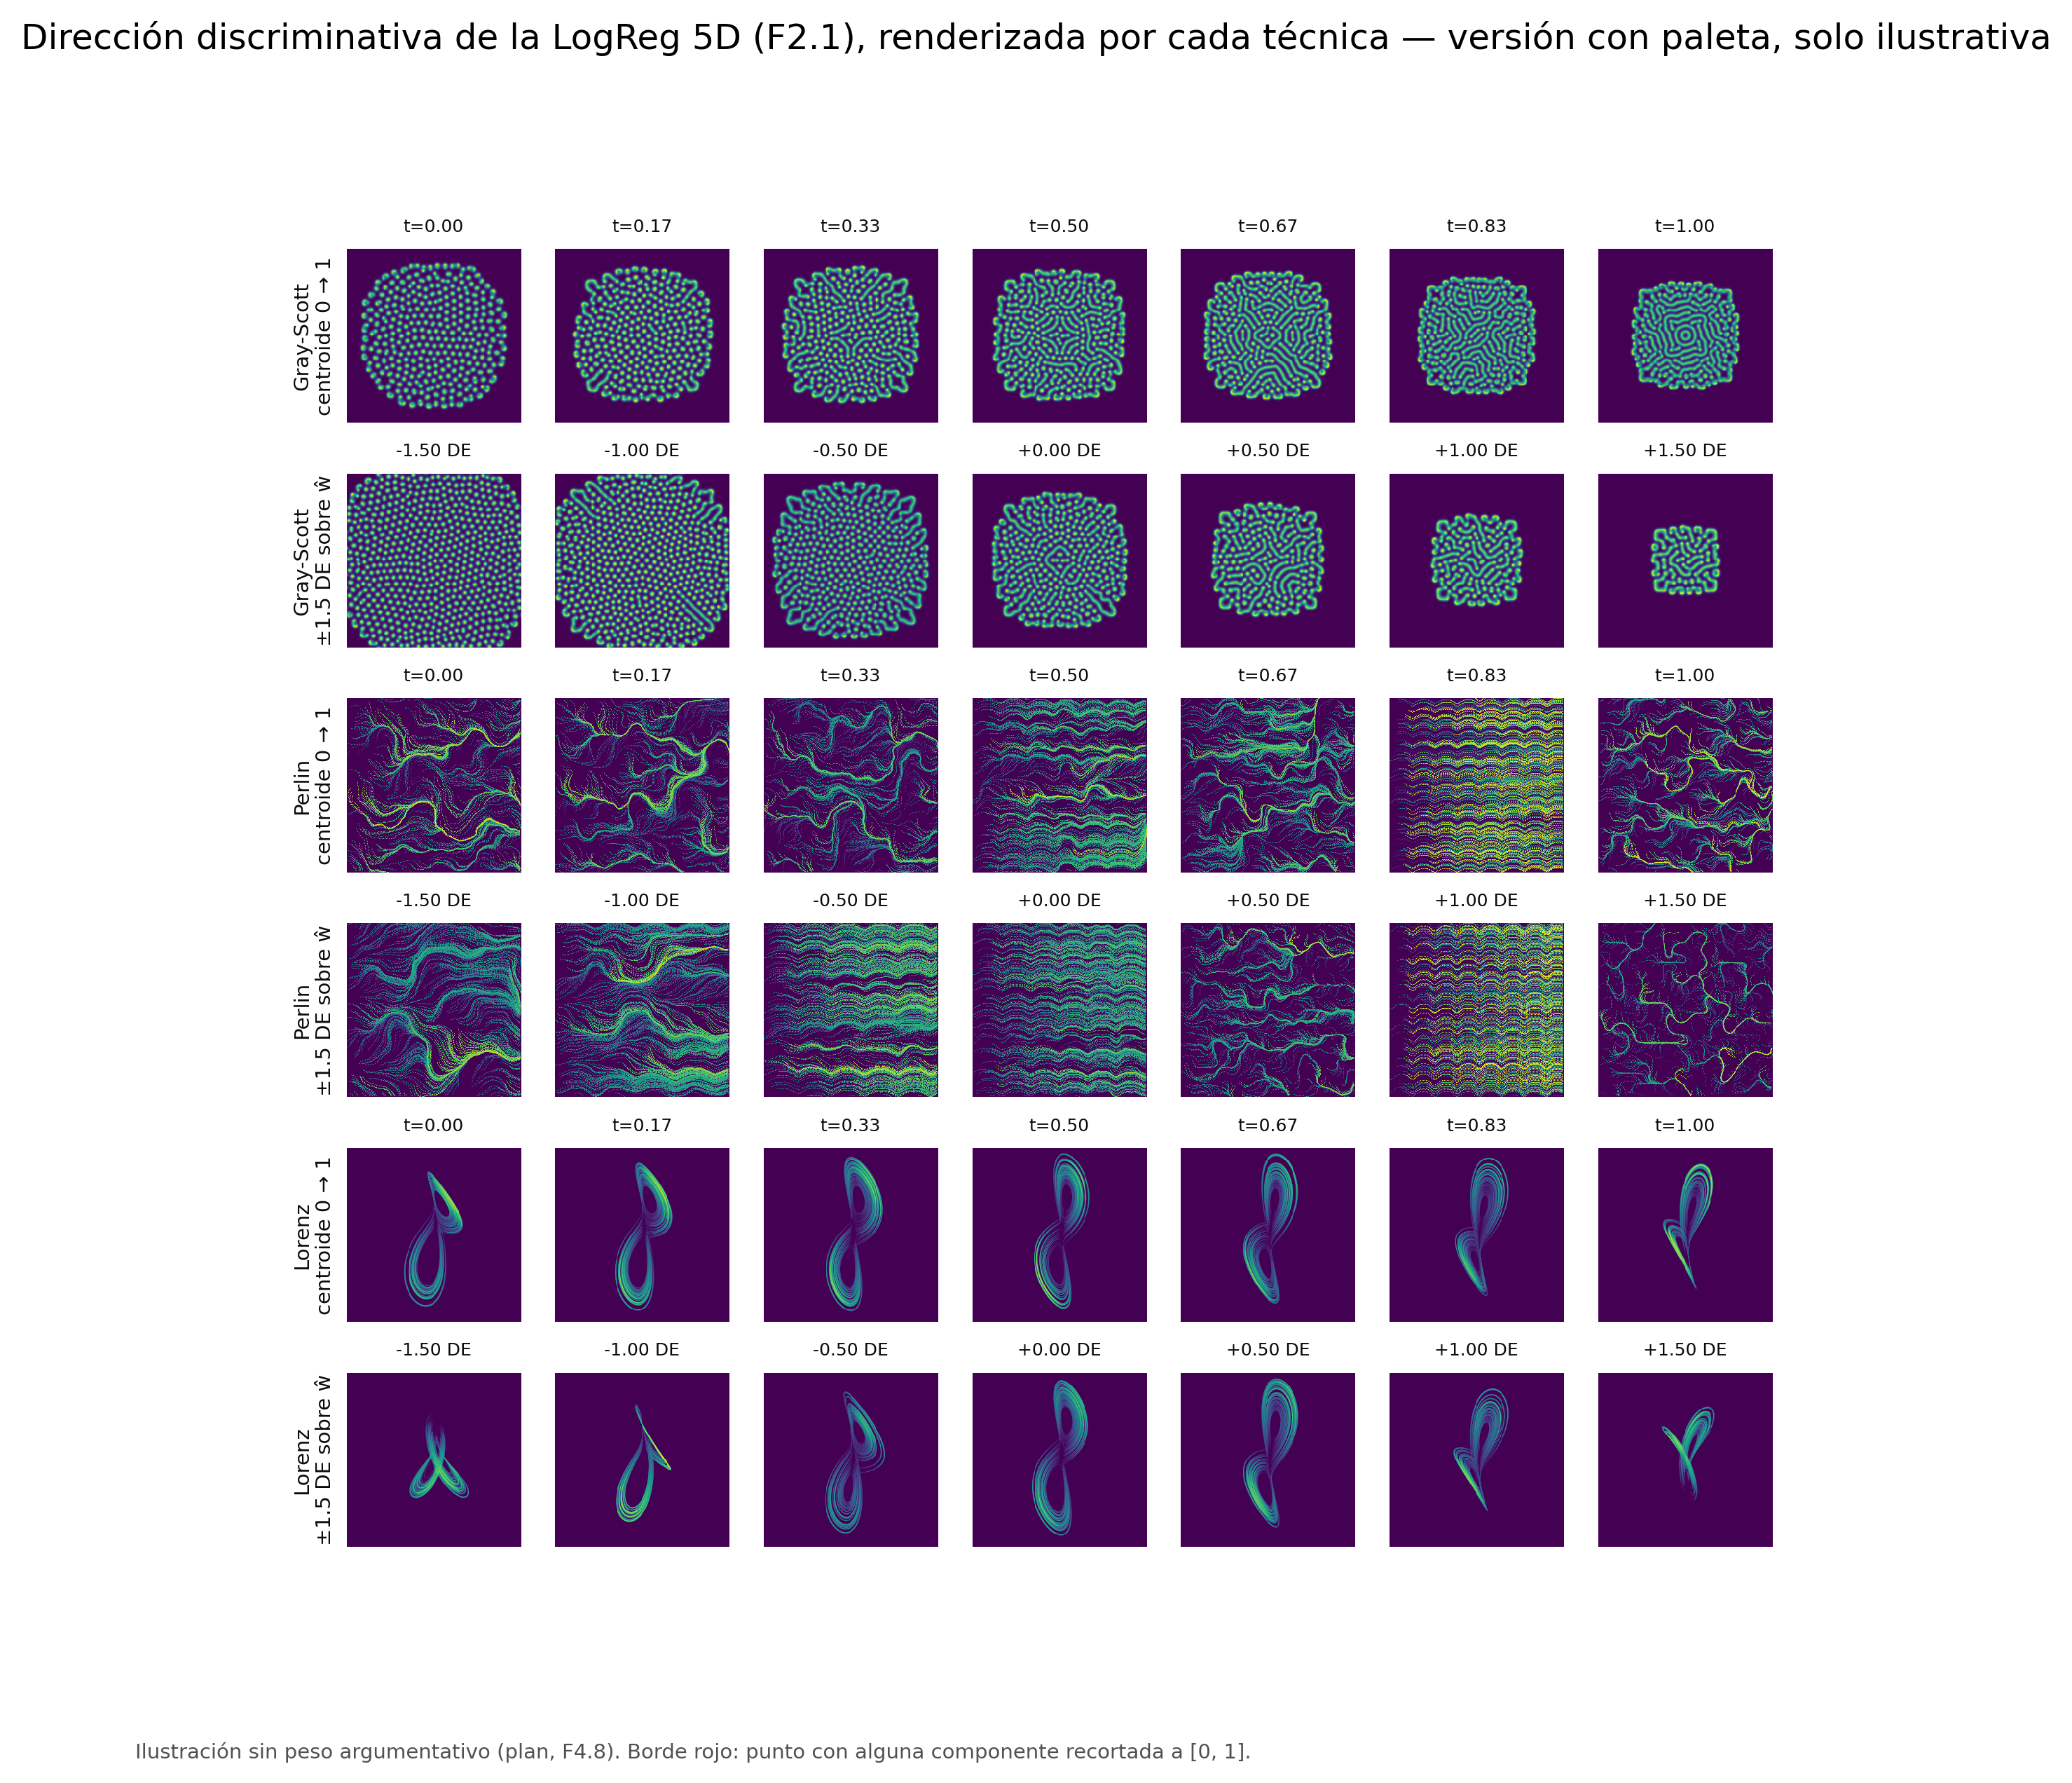

In [4]:
display(Image(filename=str(D / 'f48_direccion_paleta_ilustrativa.png'), width=900))